In [1]:
import sys
import os

sys.path.insert(0, os.path.abspath("."))
sys.path.append(os.path.abspath("../../"))

In [2]:
from desc import set_device
set_device("gpu")

In [3]:
import numpy as np
np.set_printoptions(linewidth=np.inf, precision=4, suppress=True, threshold=sys.maxsize)
import matplotlib.pyplot as plt
%matplotlib inline
import plotly.graph_objects as go
import functools
import scipy

I like to have this import all for convenience,

In [4]:
import desc

from desc.basis import *
from desc.backend import *
from desc.compute import *
from desc.coils import *
from desc.equilibrium import *
from desc.examples import *
from desc.grid import *
from desc.geometry import *
from desc.io import *

from desc.objectives import *
from desc.objectives.objective_funs import *
from desc.objectives.getters import *
from desc.objectives.normalization import compute_scaling_factors
from desc.objectives.utils import *
from desc.optimize._constraint_wrappers import *

from desc.transform import Transform
from desc.plotting import *
from desc.optimize import *
from desc.perturbations import *
from desc.profiles import *
from desc.compat import *
from desc.utils import *
from desc.magnetic_fields import *

from desc.__main__ import main
from desc.vmec_utils import vmec_boundary_subspace
from desc.input_reader import InputReader
from desc.continuation import solve_continuation_automatic

print_backend_info()

DESC version=0.17.3+411.g8a54240a7c.
Using JAX backend: jax version=0.7.2, jaxlib version=0.7.2, dtype=float64.
Using device: NVIDIA GeForce RTX 4080 Laptop GPU (id=0), with 10.84 GB available memory.


# Compare W7-X variants shown in the Paper 

In [5]:
eqp = load("./equilibria/poincare-QH-optimized-wqs3-war3-wvol0-wb1.h5")[-1]
eq_qh = load(f"./equilibria/QH_L&P_2022_output.h5")
eq_qh2 = load(f"./equilibria/QH_LCFS_(unnorm_f_qs)_output.h5")[-1]
eq_qh3 = load(f"./equilibria/QH_LCFS_output.h5")[-1]
eqs = [eqp, eq_qh, eq_qh2, eq_qh3]
labels = [
    "Poincaré",
    "L&P 2022",
    "LCFS (unnorm. f_qs)",
    "LCFS",
]
colors = ["red", "blue", "green", "magenta"]

/CODES/DESC/desc/io/hdf5_io.py:147: RuntimeWarning: 
The object attribute '_xsection' was not loaded from the file.
This is likely because the file containing 'Equilibrium' was created before '_xsection' became an attribute of objects of class '<class 'desc.equilibrium.equilibrium.Equilibrium'>'.
The user may verify that a default value has been set.
This warning will persist until the file is saved with the new object.

  warnings.warn(colored(msg, "yellow"), RuntimeWarning)


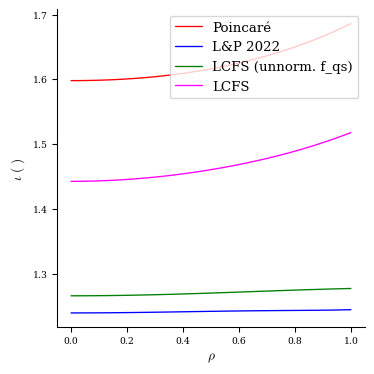

In [6]:
fig, ax = plot_1d(eqp, "iota", label=labels[0], color=colors[0])
for eq in eqs[1:]:
    plot_1d(eq, "iota", ax=ax, label=labels[eqs.index(eq)], color=colors[eqs.index(eq)]);

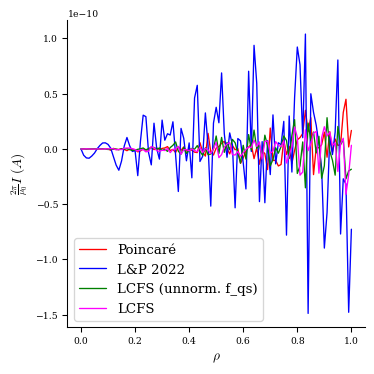

In [7]:
fig, ax = plot_1d(eqp, "current", label=labels[0], color=colors[0])
for eq in eqs[1:]:
    plot_1d(eq, "current", ax=ax, label=labels[eqs.index(eq)], color=colors[eqs.index(eq)]);

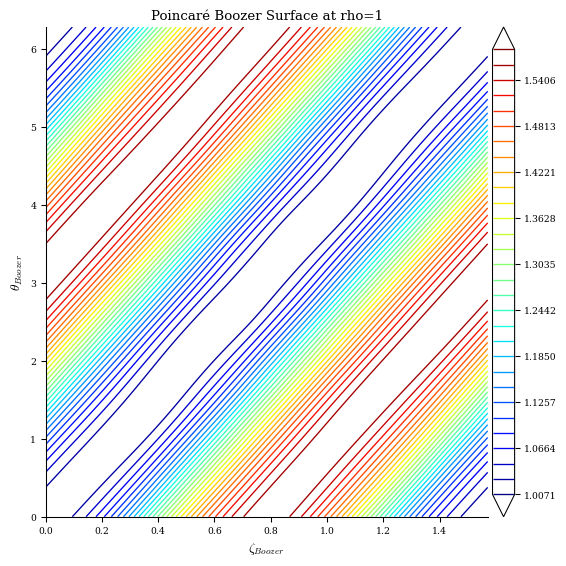

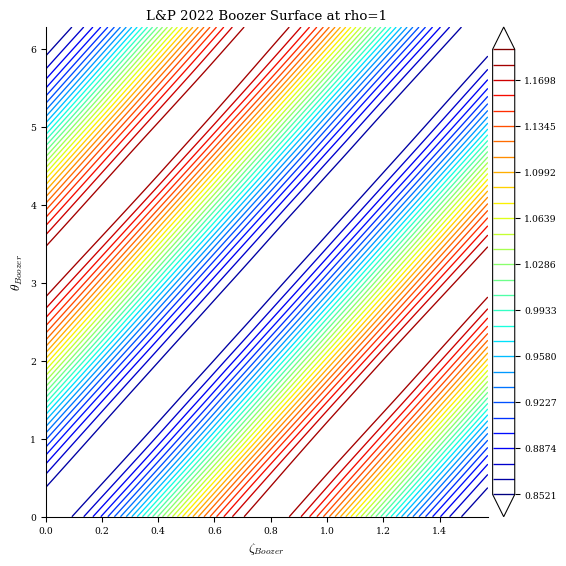

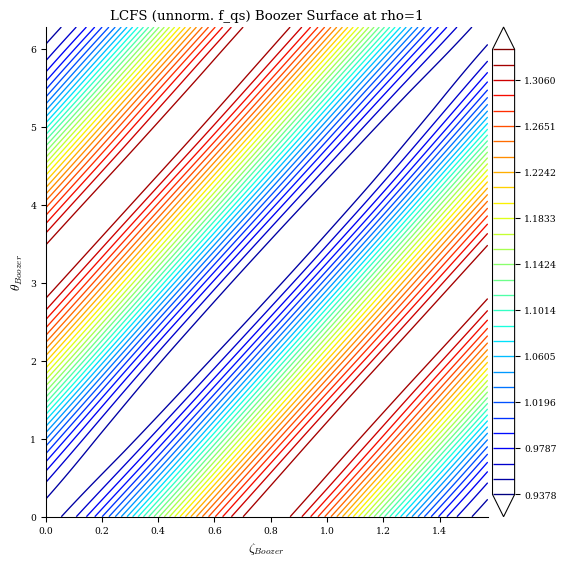

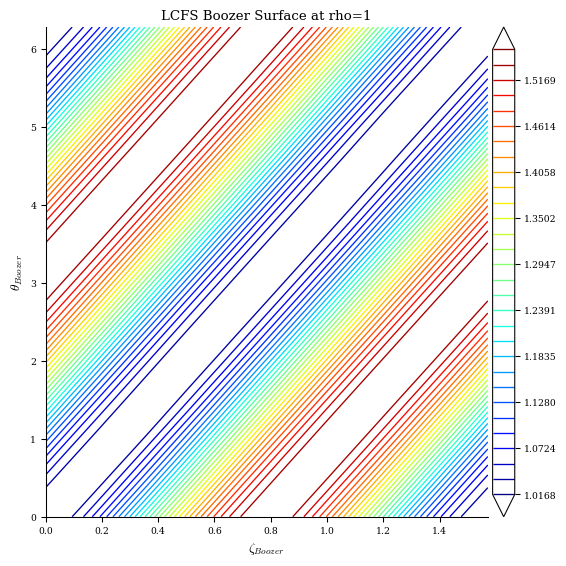

In [8]:
for eq in eqs:
    fig, ax = plot_boozer_surface(eq, rho=1)
    ax.set_title(f"{labels[eqs.index(eq)]} Boozer Surface at rho=1")

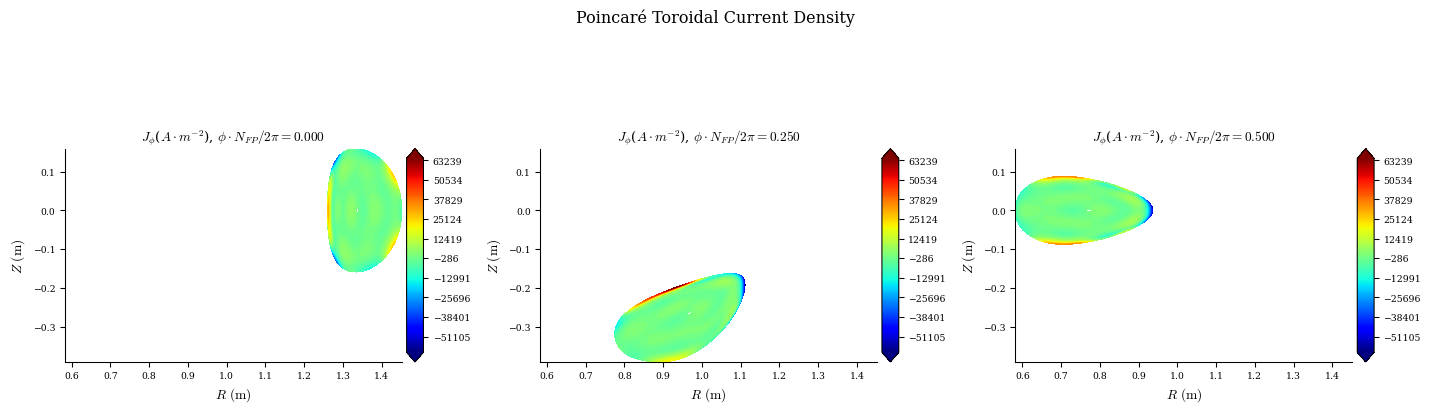

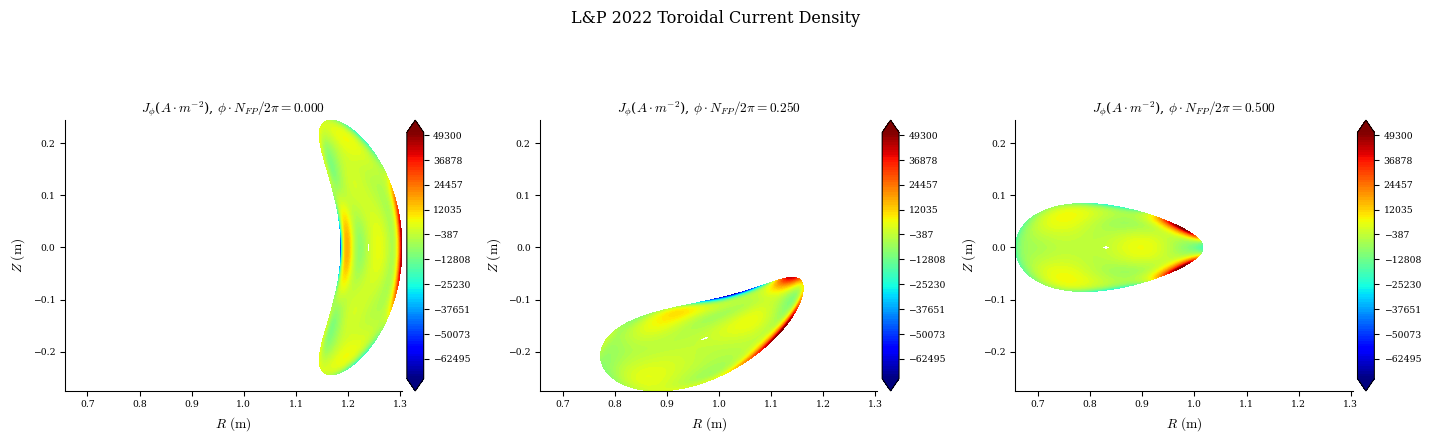

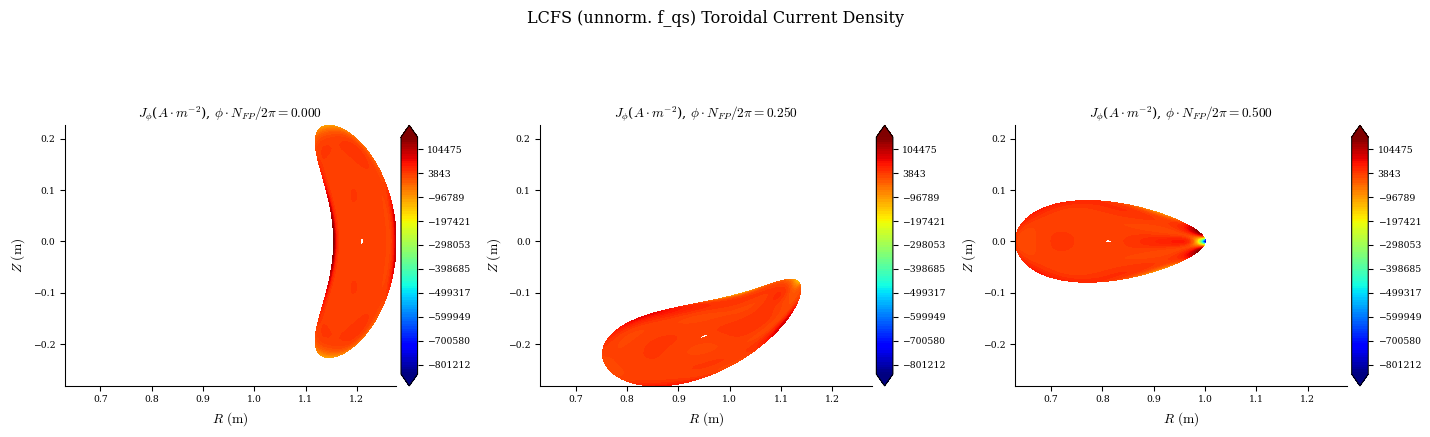

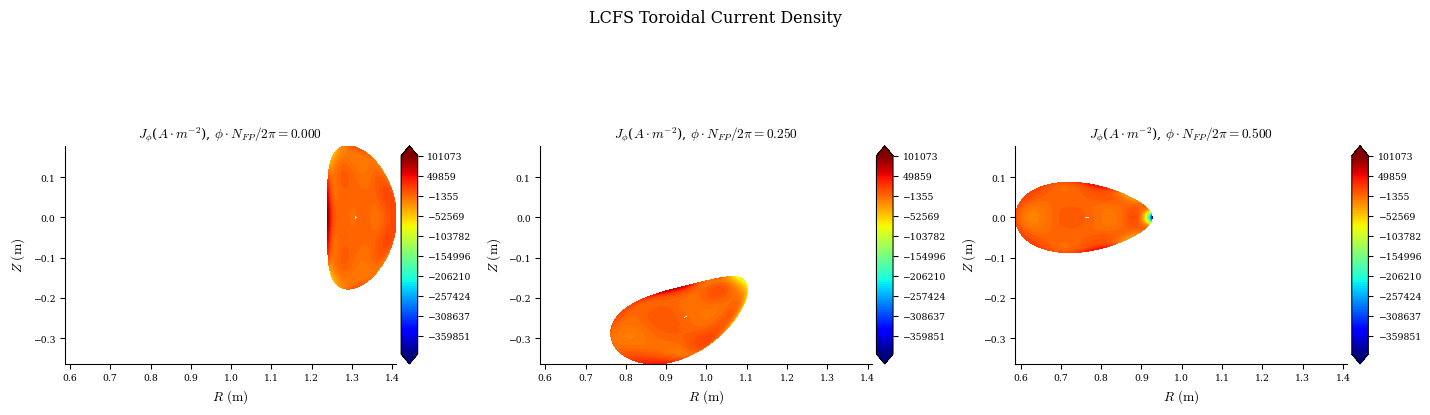

In [9]:
for eq in eqs:
    fig, ax = plot_section(eq, "J_phi", phi=np.linspace(0, np.pi / eq.NFP, 3, endpoint=True))
    fig.suptitle(f"{labels[eqs.index(eq)]} Toroidal Current Density")

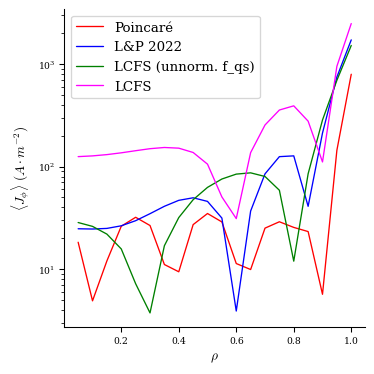

In [10]:
fig, ax = plot_fsa(eqp, "J_phi", label=labels[0], color=colors[0], log=True)
for eq in eqs[1:]:
    plot_fsa(
        eq,
        "J_phi",
        ax=ax,
        label=labels[eqs.index(eq)],
        color=colors[eqs.index(eq)],
        log=True,
    )

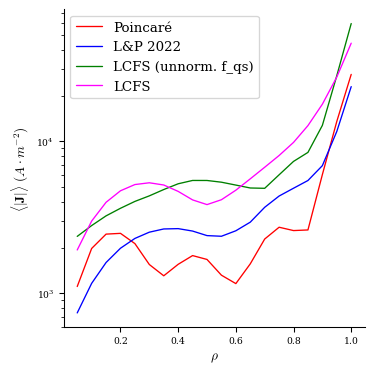

In [11]:
fig, ax = plot_fsa(eqp, "|J|", label=labels[0], color=colors[0], log=True)
for eq in eqs[1:]:
    plot_fsa(
        eq,
        "|J|",
        ax=ax,
        label=labels[eqs.index(eq)],
        color=colors[eqs.index(eq)],
        log=True,
    )

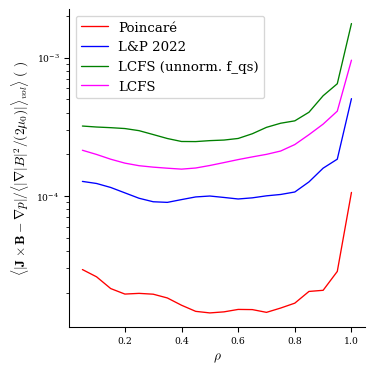

In [12]:
fig, ax = plot_fsa(eqp, "|F|_normalized", label=labels[0], color=colors[0], log=True)
for eq in eqs[1:]:
    plot_fsa(
        eq,
        "|F|_normalized",
        ax=ax,
        label=labels[eqs.index(eq)],
        color=colors[eqs.index(eq)],
        log=True,
    )

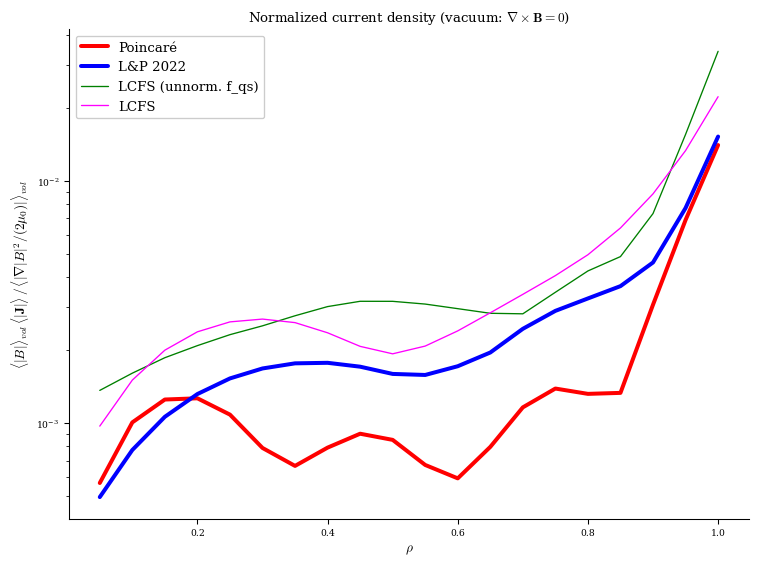

In [ ]:
eqp = load("./equilibria/poincare-QH-optimized-wqs3-war3-wvol0-wb1.h5")[-1]
eq_qh = load(f"./equilibria/QH_L&P_2022_output.h5")
eq_qh2 = load(f"./equilibria/QH_LCFS_(unnorm_f_qs)_output.h5")[-1]
eq_qh3 = load(f"./equilibria/QH_LCFS_output.h5")[-1]
eqs = [eqp, eq_qh, eq_qh2, eq_qh3]
labels = [
    "Poincaré",
    "L&P 2022",
    "LCFS (unnorm. f_qs)",
    "LCFS",
]
colors = ["red", "blue", "green", "magenta"]

fig, ax = plt.subplots(1, 1, figsize=(8, 6))
for eq, label, color in zip(eqs, labels, colors):
    lw = 3 if eq in eqs[:2] else 1
    B_vol = eq.compute("<|B|>_vol")["<|B|>_vol"]
    plot_fsa(
        eq,
        "|J|",
        normalize="<|grad(|B|^2)|/2mu0>_vol",
        log=True,
        label=label,
        color=color,
        lw=lw,
        ax=ax,
    )
    line = ax.lines[-1]
    line.set_ydata(line.get_ydata() * B_vol)

ax.relim()
ax.autoscale_view()
ax.set_ylabel(
    r"$\langle |B| \rangle_{vol} \, \langle |\mathbf{J}| \rangle"
    r" \, / \, \langle |\nabla |B|^2 / (2\mu_0)| \rangle_{vol}$"
)
ax.set_title(r"Normalized current density (vacuum: $\nabla \times \mathbf{B} = 0$)")
ax.legend(framealpha=1.0)